# EuroSAT Satellite Image Classification

**AAI-521, Group 4 | Ahmed Eldahmy**

**Team:** Ahmed Eldahmy, Akua Duffour, Sai Gautham Bandi


## 1. Imports


In [1]:
import hashlib
import json
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.21.0
GPU available: True


## 2. Set up folders

Colab files are temporary. Set `USE_GOOGLE_DRIVE` to `True` if you want
to keep the data and results in Drive.


In [2]:
USE_GOOGLE_DRIVE = False

if USE_GOOGLE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/AAI-521-Group4-Eurosat")
else:
    base = Path("/content") if Path("/content").exists() else Path.cwd()
    PROJECT_ROOT = base / "AAI-521-Group4-Eurosat"

RAW_DIR = PROJECT_ROOT / "raw_dataset"
DATA_DIR = PROJECT_ROOT / "data"
SRC_DIR = PROJECT_ROOT / "src"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (RAW_DIR, DATA_DIR, SRC_DIR, RESULTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Saving files to:", PROJECT_ROOT)


Saving files to: /content/AAI-521-Group4-Eurosat


## 3. Download EuroSAT

We download the RGB images from the official Zenodo page. The ZIP is about
95 MB. Downloading and extracting it may take a few minutes. If the download fails, open the [Zenodo page](https://zenodo.org/records/7711810)
in your browser and download EuroSAT_RGB.zip. Upload the ZIP to
RAW_DIR and run this cell again.


In [3]:
DATA_URL = "https://zenodo.org/api/records/7711810/files/EuroSAT_RGB.zip/content"
ZIP_PATH = RAW_DIR / "EuroSAT_RGB.zip"
# Checksum published on the EuroSAT Zenodo page.
EXPECTED_MD5 = "f46e308c4d50d4bf32fedad2d3d62f3b"

if not ZIP_PATH.exists():
    print("Downloading from Zenodo...")
    temporary_zip = RAW_DIR / "EuroSAT_RGB.download"
    try:
        with requests.get(
            DATA_URL, stream=True, timeout=(30, 180),
            headers={"User-Agent": "Mozilla/5.0"},
        ) as response:
            response.raise_for_status()
            with temporary_zip.open("wb") as out:
                for block in response.iter_content(chunk_size=1024 * 1024):
                    if block:
                        out.write(block)
        temporary_zip.replace(ZIP_PATH)
    except requests.RequestException as err:
        raise RuntimeError(
            "Could not download EuroSAT from Zenodo. "
            "Download EuroSAT_RGB.zip in a browser and place it in RAW_DIR."
        ) from err

file_md5 = hashlib.md5()
with ZIP_PATH.open("rb") as zipped:
    for block in iter(lambda: zipped.read(1024 * 1024), b""):
        file_md5.update(block)
assert file_md5.hexdigest() == EXPECTED_MD5, (
    "The ZIP checksum is different from the official file. "
    "Check the download before continuing."
)
print("ZIP downloaded and verified:", ZIP_PATH)

marker = RAW_DIR / "extraction_complete.txt"
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        # Check paths before unpacking the archive.
        base = RAW_DIR.resolve()
        for item in archive.infolist():
            target = (RAW_DIR / item.filename).resolve()
            assert target.is_relative_to(base), "Unexpected path in ZIP."
        archive.extractall(RAW_DIR)
    marker.write_text("EuroSAT RGB extracted\n", encoding="utf-8")
print("Images extracted to:", RAW_DIR)


ZIP downloaded and verified: /content/AAI-521-Group4-Eurosat/raw_dataset/EuroSAT_RGB.zip
Images extracted to: /content/AAI-521-Group4-Eurosat/raw_dataset


## 4. Check the images and labels


In [4]:
CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation", "Highway",
    "Industrial", "Pasture", "PermanentCrop", "Residential",
    "River", "SeaLake",
]
NAME_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

image_paths = sorted(
    p for p in RAW_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}
)
print("Images found:", len(image_paths))
print("Classes:", len(CLASS_NAMES))
assert len(image_paths) == 27000, "Expected 27,000 JPEG images."

unexpected = sorted({p.parent.name for p in image_paths} - set(CLASS_NAMES))
assert not unexpected, f"Unexpected class folders: {unexpected}"

rows = []
example_images = {}
for path in image_paths:
    class_name = path.parent.name
    with Image.open(path) as opened:
        original_mode = opened.mode
        image = np.array(opened.convert("RGB"))
    class_id = NAME_TO_ID[class_name]
    rows.append(
        {
            "filename": path.relative_to(RAW_DIR).as_posix(),
            "label": class_id,
            "class_name": class_name,
            "height": image.shape[0],
            "width": image.shape[1],
            "channels": image.shape[2],
            "mode": original_mode,
            "image_hash": hashlib.sha256(image.tobytes()).hexdigest(),
        }
    )
    if class_id not in example_images:
        example_images[class_id] = image

image_df = pd.DataFrame(rows).sort_values("filename").reset_index(drop=True)
display(image_df[["filename", "label", "class_name", "height", "width"]].head())


Images found: 27000
Classes: 10


,filename,label,class_name,height,width
0,EuroSAT_RGB/AnnualCrop/AnnualCrop_1.jpg,0,AnnualCrop,64,64
1,EuroSAT_RGB/AnnualCrop/AnnualCrop_10.jpg,0,AnnualCrop,64,64
2,EuroSAT_RGB/AnnualCrop/AnnualCrop_100.jpg,0,AnnualCrop,64,64
3,EuroSAT_RGB/AnnualCrop/AnnualCrop_1000.jpg,0,AnnualCrop,64,64
4,EuroSAT_RGB/AnnualCrop/AnnualCrop_1001.jpg,0,AnnualCrop,64,64


## 5. A few sample images


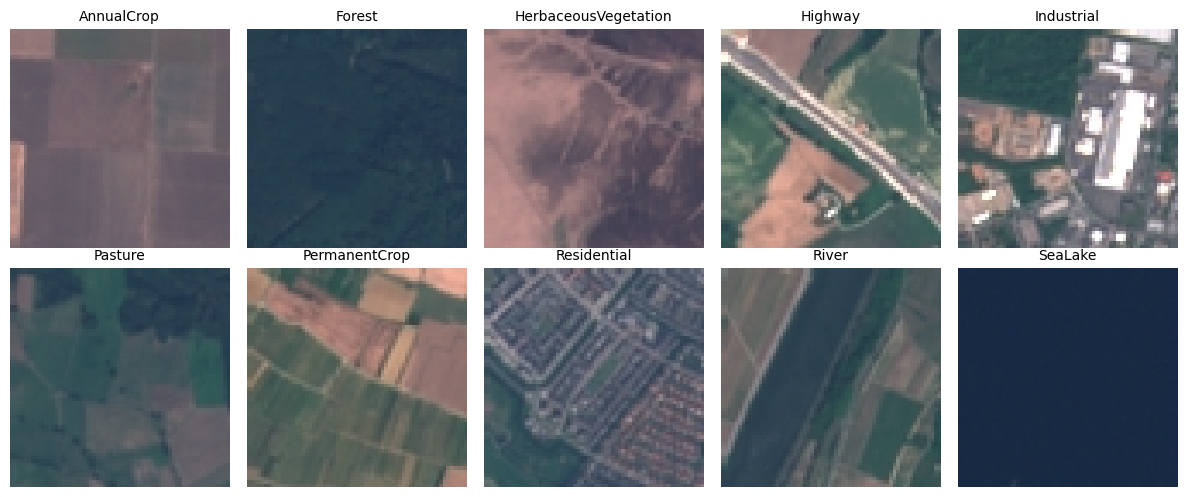

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    ax.imshow(example_images[class_id])
    ax.set_title(CLASS_NAMES[class_id], fontsize=10)
    ax.axis("off")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "eda_samples.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. How many images are in each class?


,Images
class_name,
AnnualCrop,3000
Forest,3000
HerbaceousVegetation,3000
Highway,2500
Industrial,2500
Pasture,2000
PermanentCrop,2500
Residential,3000
River,2500


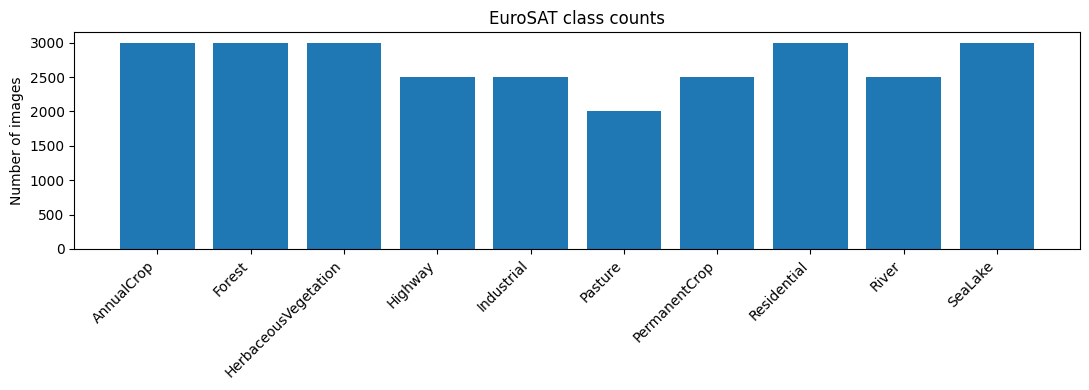

In [6]:
class_counts = (
    image_df["class_name"].value_counts().reindex(CLASS_NAMES)
)
display(class_counts.rename("Images").to_frame())

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(class_counts.index, class_counts.values)
ax.set_ylabel("Number of images")
ax.set_title("EuroSAT class counts")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "eda_class_counts.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Check for problems

I checked the image sizes, filenames, and exact duplicates.
If a check fails, we should look at the images before making the split.
This does not catch every near-duplicate.


In [7]:
checks = {
    "missing_filenames": int(image_df["filename"].isna().sum()
                             + image_df["filename"].eq("").sum()),
    "duplicate_filenames": int(image_df["filename"].duplicated().sum()),
    "exact_duplicate_images": int(image_df["image_hash"].duplicated().sum()),
    "wrong_shape": int((~(
        image_df["height"].eq(64)
        & image_df["width"].eq(64)
        & image_df["channels"].eq(3)
    )).sum()),
    "non_rgb_images": int(image_df["mode"].ne("RGB").sum()),
}
display(pd.Series(checks, name="Count").to_frame())
assert len(image_df) == 27000
assert set(image_df["class_name"]) == set(CLASS_NAMES)
assert all(count == 0 for count in checks.values()), (
    "A data check failed. Review the counts above."
)
print("Checks passed. Ready to split.")


,Count
missing_filenames,0
duplicate_filenames,0
exact_duplicate_images,0
wrong_shape,0
non_rgb_images,0


Checks passed. Ready to split.


## 8. Make one split for the whole team

We use 70% for training, 15% for validation, and 15% for testing.
The seed is 42. If the split file already exists, we reuse it.
Akua and Sai should use the same file.


In [8]:
SPLIT_SEED = 42
split_path = DATA_DIR / "split.csv"

if split_path.exists():
    split_df = pd.read_csv(split_path)
    print("Reusing:", split_path)
else:
    train_df, other_df = train_test_split(
        image_df, test_size=0.30,
        stratify=image_df["label"], random_state=SPLIT_SEED,
    )
    val_df, test_df = train_test_split(
        other_df, test_size=0.50,
        stratify=other_df["label"], random_state=SPLIT_SEED,
    )
    split_df = pd.concat(
        [
            train_df.assign(split="train"),
            val_df.assign(split="val"),
            test_df.assign(split="test"),
        ],
        ignore_index=True,
    )
    split_df = split_df[
        ["filename", "label", "class_name", "split"]
    ].sort_values("filename").reset_index(drop=True)
    split_df.to_csv(split_path, index=False)
    print("Created:", split_path)

assert len(split_df) == len(image_df)
assert split_df["filename"].is_unique
assert set(split_df["filename"]) == set(image_df["filename"])
assert set(split_df["split"]) == {"train", "val", "test"}
old_labels = image_df.set_index("filename")["label"]
new_labels = split_df.set_index("filename")["label"].astype(int)
assert new_labels.equals(old_labels), "Split labels do not match the images."
assert (split_df.groupby("label")["split"].nunique() == 3).all()
print(split_df["split"].value_counts().to_dict())
display(pd.crosstab(split_df["class_name"], split_df["split"]))


Created: /content/AAI-521-Group4-Eurosat/data/split.csv
{'train': 18900, 'val': 4050, 'test': 4050}


split,test,train,val
class_name,,,
AnnualCrop,450,2100,450
Forest,450,2100,450
HerbaceousVegetation,450,2100,450
Highway,375,1750,375
Industrial,375,1750,375
Pasture,300,1400,300
PermanentCrop,375,1750,375
Residential,450,2100,450
River,375,1750,375


## 9. Save the files Akua and Sai need

The split CSV tells us which images go where. The class map gives the label
numbers. The loader reads the images from the extracted Zenodo folder.


In [9]:
class_map_path = DATA_DIR / "class_map.json"
class_map = {
    "dataset": "EuroSAT_RGB.zip",
    "source": "https://zenodo.org/records/7711810",
    "archive_md5": EXPECTED_MD5,
    "split_seed": SPLIT_SEED,
    "class_names": CLASS_NAMES,
    "name_to_id": NAME_TO_ID,
}
if class_map_path.exists():
    assert json.loads(class_map_path.read_text()) == class_map, (
        "An older class map is different. Please review it first."
    )
else:
    class_map_path.write_text(json.dumps(class_map, indent=2) + "\n")

LOADER_CODE = r'''# Shared EuroSAT image loader for Group 4.
from pathlib import Path

import pandas as pd
import tensorflow as tf


def load_eurosat_split(split_csv, image_root, split, batch_size=64, seed=42):
    # Input images are uint8 RGB. Each model handles its own scaling.
    if split not in {"train", "val", "test"}:
        raise ValueError("Split must be train, val, or test.")

    df = pd.read_csv(split_csv)
    if not {"filename", "label", "split"}.issubset(df.columns):
        raise ValueError("split.csv is missing required columns.")
    if df["filename"].duplicated().any():
        raise ValueError("Duplicate filenames in split.csv.")

    part = df.loc[df["split"] == split].copy()
    if part.empty:
        raise ValueError(f"No images found for split {split}.")

    root = Path(image_root)
    paths = [str(root / p) for p in part["filename"].astype(str)]
    if not all(Path(p).is_file() for p in paths):
        raise FileNotFoundError("Some images are missing. Check image_root.")
    labels = part["label"].astype("int32").to_numpy()

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def decode_image(path, label):
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        image = tf.ensure_shape(image, (64, 64, 3))
        return image, tf.cast(label, tf.int32)

    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()
    if split == "train":
        ds = ds.shuffle(
            min(len(part), 10000),
            seed=seed,
            reshuffle_each_iteration=True,
        )
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
'''
import textwrap
loader_path = SRC_DIR / "eurosat_loader.py"
loader_text = textwrap.dedent(LOADER_CODE).lstrip()
if loader_path.exists():
    assert loader_path.read_text() == loader_text, (
        "The saved loader is different. Review before overwriting."
    )
else:
    loader_path.write_text(loader_text, encoding="utf-8")

print("Saved:", split_path)
print("Saved:", class_map_path)
print("Saved:", loader_path)


Saved: /content/AAI-521-Group4-Eurosat/data/split.csv
Saved: /content/AAI-521-Group4-Eurosat/data/class_map.json
Saved: /content/AAI-521-Group4-Eurosat/src/eurosat_loader.py


## 10. Test the shared data loader

Read each split once to check the image count. This also fills the cache
so the next training epochs run faster.


In [10]:
import importlib.util

spec = importlib.util.spec_from_file_location("eurosat_loader", loader_path)
shared_loader = importlib.util.module_from_spec(spec)
spec.loader.exec_module(shared_loader)

BATCH_SIZE = 64
train_ds = shared_loader.load_eurosat_split(
    split_path, RAW_DIR, "train", BATCH_SIZE, SEED
)
val_ds = shared_loader.load_eurosat_split(
    split_path, RAW_DIR, "val", BATCH_SIZE, SEED
)
test_ds = shared_loader.load_eurosat_split(
    split_path, RAW_DIR, "test", BATCH_SIZE, SEED
)

for name, ds in (("train", train_ds), ("val", val_ds), ("test", test_ds)):
    total = 0
    for images, labels in ds:
        assert tuple(images.shape[1:]) == (64, 64, 3)
        assert images.dtype == tf.uint8
        total += int(labels.shape[0])
    assert total == int((split_df["split"] == name).sum())
    print(f"{name}: {total} images")


train: 18900 images
val: 4050 images
test: 4050 images


## 11. Make a ZIP for the team

This ZIP is small. It does not include the 27,000 images.
Akua and Sai can download the same EuroSAT ZIP from Zenodo.


In [11]:
handoff_zip = PROJECT_ROOT / "EuroSAT_Team_Handoff.zip"
with zipfile.ZipFile(handoff_zip, "w", zipfile.ZIP_DEFLATED) as out:
    out.write(split_path, "data/split.csv")
    out.write(class_map_path, "data/class_map.json")
    out.write(loader_path, "src/eurosat_loader.py")
print("Ready to share:", handoff_zip)

# Download the ZIP in Colab if needed:
# from google.colab import files
# files.download(str(handoff_zip))


Ready to share: /content/AAI-521-Group4-Eurosat/EuroSAT_Team_Handoff.zip


## 12. Model A: basic CNN

The CNN learns patterns from the RGB pixels. I scale the values to 0–1
and add small flips and rotations during training.


In [12]:
from tensorflow.keras import layers, models

model_a = models.Sequential(
    [
        layers.Input(shape=(64, 64, 3)),
        layers.Rescaling(1.0 / 255),
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.10),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(10, activation="softmax"),
    ],
    name="baseline_cnn",
)
model_a.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model_a.summary()


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

## 13. Train the CNN

Training uses only the training set. I check validation loss after each epoch
and save the best model.


In [13]:
EPOCHS = 20
best_model_path = MODELS_DIR / "model_a_best.keras"
history = model_a.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(best_model_path), monitor="val_loss", save_best_only=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", patience=2, factor=0.5, min_lr=1e-5
        ),
    ],
)

history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "epoch"
history_df.to_csv(RESULTS_DIR / "model_a_history.csv")
print("Best epoch:", int(history_df["val_loss"].idxmin()))


Epoch 1/20
296/296 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.4597 - loss: 1.4754 - val_accuracy: 0.4914 - val_loss: 1.2829 - learning_rate: 0.0010
Epoch 2/20
296/296 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.6360 - loss: 1.0282 - val_accuracy: 0.7106 - val_loss: 0.8050 - learning_rate: 0.0010
Epoch 3/20
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7214 - loss: 0.8026 - val_accuracy: 0.7225 - val_loss: 0.7742 - learning_rate: 0.0010
Epoch 4/20
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7441 - loss: 0.7234 - val_accuracy: 0.7375 - val_loss: 0.7314 - learning_rate: 0.0010
Epoch 5/20
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7605 - loss: 0.6754 - val_accuracy: 0.7477 - val_loss: 0.7136 - learning_rate: 0.0010
Epoch 6/20
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7817 - loss: 0.6233 - val_accuracy: 0.7659 - val_loss: 0.6407 - learning_rate: 0.0010
Epoch 7/20
296/296 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7934 - loss: 0

## 14. Test the best model

I use the test set only after training. Accuracy shows the overall result,
and F1 helps show how the model did across the 10 classes.


In [14]:
model_a = tf.keras.models.load_model(str(best_model_path))
test_loss, test_accuracy = model_a.evaluate(test_ds)
true_labels = np.concatenate([y.numpy() for _, y in test_ds])
predictions = model_a.predict(test_ds).argmax(axis=1)
assert len(true_labels) == len(predictions) == (
    split_df["split"].eq("test").sum()
)
precision, recall, f1, _ = precision_recall_fscore_support(
    true_labels, predictions, average="macro", zero_division=0
)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {f1:.4f}")
print(
    classification_report(
        true_labels, predictions,
        labels=list(range(10)), target_names=CLASS_NAMES, zero_division=0,
    )
)


64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8906 - loss: 0.3153
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Test accuracy: 0.8906
Macro F1: 0.8865
                      precision    recall  f1-score   support

          AnnualCrop       0.93      0.85      0.89       450
              Forest       0.97      0.98      0.97       450
HerbaceousVegetation       0.88      0.87      0.87       450
             Highway       0.83      0.72      0.77       375
          Industrial       0.93      0.91      0.92       375
             Pasture       0.88      0.92      0.90       300
       PermanentCrop       0.78      0.79      0.78       375
         Residential       0.84      0.99      0.91       450
               River       0.86      0.87      0.87       375
             SeaLake       0.98      0.98      0.98       450

            accuracy                           0.89      4050
           macro avg       0.89      0.89      0.89      4050
        weighted avg       0.89      0.89

## 15. Training curves and confusion matrix


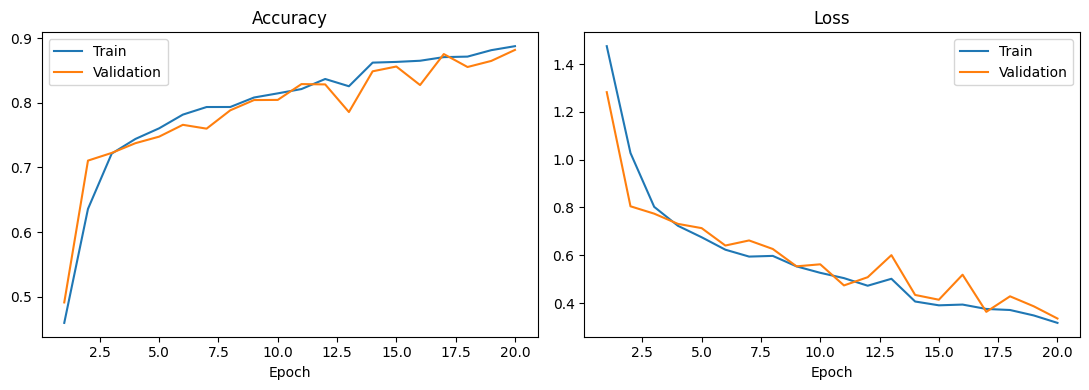

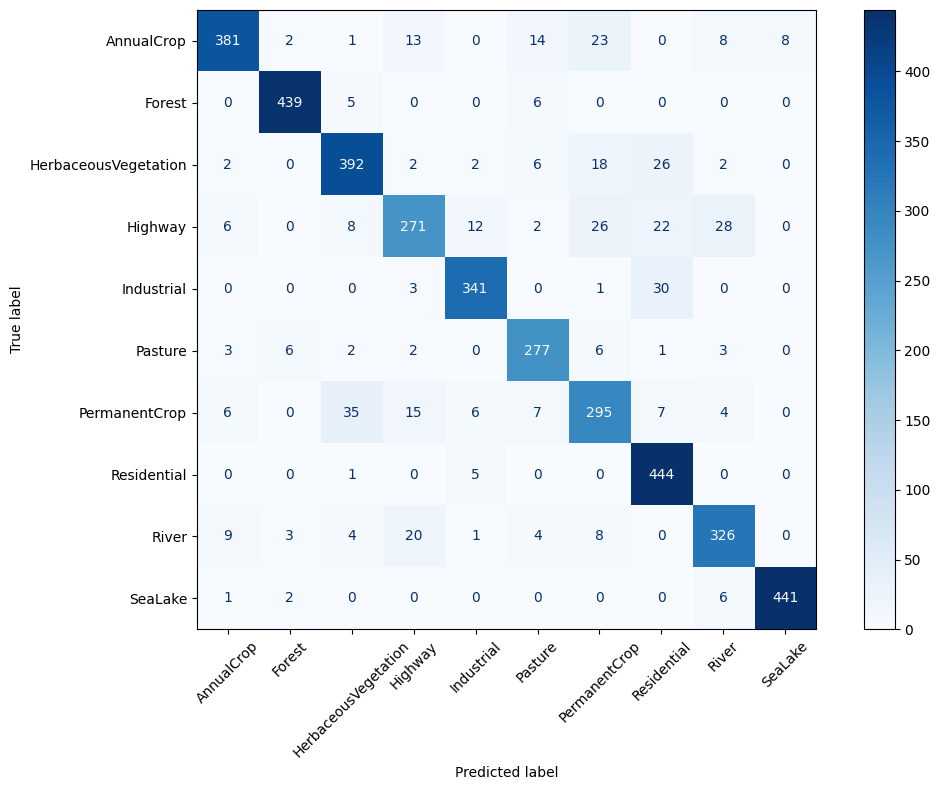

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df.index, history_df["accuracy"], label="Train")
axes[0].plot(history_df.index, history_df["val_accuracy"], label="Validation")
axes[0].set(title="Accuracy", xlabel="Epoch")
axes[0].legend()
axes[1].plot(history_df.index, history_df["loss"], label="Train")
axes[1].plot(history_df.index, history_df["val_loss"], label="Validation")
axes[1].set(title="Loss", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
fig.savefig(RESULTS_DIR / "model_a_curves.png", dpi=160, bbox_inches="tight")
plt.show()

cm = confusion_matrix(true_labels, predictions, labels=list(range(10)))
fig, ax = plt.subplots(figsize=(11, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", values_format="d"
)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "model_a_confusion.png", dpi=160, bbox_inches="tight")
plt.show()
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    RESULTS_DIR / "model_a_confusion.csv"
)


## 16. Save Model A results

Sai can use this JSON to compare the CNN with the other two models.
In my report section, I'll explain the loss curves and the classes the
model confused most often.


In [16]:
best_epoch = int(history_df["val_loss"].idxmin())
best_train_acc = float(history_df.loc[best_epoch, "accuracy"])
best_val_acc = float(history_df.loc[best_epoch, "val_accuracy"])
results = {
    "model": "A - Baseline CNN",
    "dataset": "EuroSAT RGB (Zenodo)",
    "split_seed": SPLIT_SEED,
    "train_count": int(split_df["split"].eq("train").sum()),
    "val_count": int(split_df["split"].eq("val").sum()),
    "test_count": int(split_df["split"].eq("test").sum()),
    "best_epoch": best_epoch,
    "best_epoch_train_accuracy": best_train_acc,
    "best_epoch_validation_accuracy": best_val_acc,
    "best_epoch_accuracy_gap": best_train_acc - best_val_acc,
    "best_validation_loss": float(history_df["val_loss"].min()),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_macro_precision": float(precision),
    "test_macro_recall": float(recall),
    "test_macro_f1": float(f1),
    "parameters": int(model_a.count_params()),
}
metrics_path = RESULTS_DIR / "model_a_metrics.json"
metrics_path.write_text(json.dumps(results, indent=2) + "\n")
display(pd.DataFrame([results]).T.rename(columns={0: "Value"}))
print("Saved:", metrics_path)


,Value
model,A - Baseline CNN
dataset,EuroSAT RGB (Zenodo)
split_seed,42
train_count,18900
val_count,4050
test_count,4050
best_epoch,20
best_epoch_train_accuracy,0.887513
best_epoch_validation_accuracy,0.881728
best_epoch_accuracy_gap,0.005785


Saved: /content/AAI-521-Group4-Eurosat/results/model_a_metrics.json


## 17. What's left for me?

- [ ] Check the image and class counts.
- [ ] Upload `split.csv`, `class_map.json`, and `eurosat_loader.py` to GitHub.
- [ ] Ask Akua and Sai to use the same Zenodo download and split file.
- [ ] Upload this notebook and Model A's results.
- [ ] Write my part of the report using the real results.

The team will then compare all three models and finish the report and video.

**Important:** This notebook is ready for Colab, but the full download
and training still need to run there.
